In [36]:
import numpy as np
import matplotlib.pyplot as plt


class TapeMesh2D:
    def __init__(self, nx=2000, length_m=0.20, width_m=12e-3):
        self.nx = nx
        self.length_m = length_m
        self.width_m = width_m
        self.dx = length_m / nx
        self.max_rebco_ratio = 1.0      # start dumping current once REBCO reaches Ic
        self.rho_stabilizer = 1e-8      # lower toy resistivity than before

        self.layers = [
            {"name": "cu_top", "n": 25, "dy": 0.8e-6, "mat": 1},
            {"name": "ag_top", "n": 4, "dy": 0.5e-6, "mat": 2},
            {"name": "rebco", "n": 1, "dy": 1.0e-6, "mat": 3},
            {
                "name": "hastelloy",
                "n": 10,
                "edges": np.array([0, 0.5, 1, 2, 5, 10, 15, 18, 19, 19.5, 20]) * 1e-6,
                "mat": 4,
            },
            {"name": "ag_bottom", "n": 4, "dy": 0.5e-6, "mat": 2},
            {"name": "cu_bottom", "n": 25, "dy": 0.8e-6, "mat": 1},
        ]

        self._build()

    def _build(self):
        dy = []
        layer_names = []
        material_ids = []

        for layer in self.layers:
            if "edges" in layer:
                layer_dy = np.diff(layer["edges"])
            else:
                layer_dy = np.full(layer["n"], layer["dy"])

            for i in range(len(layer_dy)):
                dy.append(layer_dy[i])
                layer_names.append(layer["name"])
                material_ids.append(layer["mat"])

        self.dy = np.array(dy)
        self.layer_names = np.array(layer_names)
        self.material_y = np.array(material_ids)
        self.ny = len(self.dy)

        self.x_edges = np.linspace(0, self.length_m, self.nx + 1)
        self.x_centers = 0.5 * (self.x_edges[:-1] + self.x_edges[1:])

        self.y_edges = np.concatenate([[0.0], np.cumsum(self.dy)])
        self.y_centers = 0.5 * (self.y_edges[:-1] + self.y_edges[1:])

        self.material_id = np.repeat(self.material_y[:, None], self.nx, axis=1)

    def rows(self, name):
        return np.where(self.layer_names == name)[0]

    def empty_field(self, val=0.0):
        return np.full((self.ny, self.nx), val, dtype=float)


class REBCOModel:
    def __init__(self):
        self.T_table = np.array([77, 80, 82, 85, 88, 90, 91, 92], dtype=float)
        self.Jc_table = np.array(
            [3e10, 2.4e10, 2e10, 1.4e10, 8e9, 3.5e9, 1.5e9, 2e8],
            dtype=float,
        )
        self.n_table = np.array([30, 27, 25, 21, 16, 11, 7, 4], dtype=float)

        self.Ec = 1e-4
        self.max_ratio_for_E = 5.0

    def Jc(self, T):
        return np.interp(T, self.T_table, self.Jc_table)

    def n(self, T):
        return np.interp(T, self.T_table, self.n_table)

    def E(self, J, T):
        Jc = self.Jc(T)
        n_val = self.n(T)

        ratio = np.abs(J) / np.maximum(Jc, 1e-12)
        ratio = np.clip(ratio, 1e-3, self.max_ratio_for_E)

        return self.Ec * ratio ** n_val

    def J_over_Jc(self, J, T):
        return np.abs(J) / np.maximum(self.Jc(T), 1e-12)


class ToyElectroThermalTape:
    """
    Toy electrothermal tape model with first-pass current redistribution.

    Assumptions:
    - REBCO and stabilizer are electrically parallel.
    - Stabilizer is lumped Cu/Ag/Hastelloy.
    - REBCO follows power-law E-J.
    - Stabilizer follows Ohm's law: E = rho * J.
    - Both paths share the same electric field.
    - Current split is solved from:
          I = A_sc * J_sc(E) + A_st * J_st(E)
    - Still no spatial current diffusion along x.
    """

    def __init__(self, mesh, rebco):
        self.mesh = mesh
        self.rebco = rebco

        self.T_bath = 77.0
        self.T_max_clip = 120.0

        self.T = mesh.empty_field(self.T_bath)
        self.J = mesh.empty_field(0.0)
        self.E = mesh.empty_field(0.0)
        self.Q = mesh.empty_field(0.0)

        self.time = 0.0
        self.I_total = 0.0

        self.rebco_row = mesh.rows("rebco")[0]
        self.A_rebco = mesh.width_m * mesh.dy[self.rebco_row]

        self.stabilizer_rows = np.where(mesh.layer_names != "rebco")[0]
        self.A_stabilizer = mesh.width_m * np.sum(mesh.dy[self.stabilizer_rows])

        # Toy stabilizer resistivity [ohm m].
        # This is deliberately approximate.
        self.rho_stabilizer = 1e-7

        # Thermal constants
        self.heat_capacity_eff = 3.0e6
        self.k_x_eff = 10.0
        self.k_y_eff = 10.0
        self.cooling_rate = 0.2

        self.joule_heat_scale = 0.01
        self.vertical_mix_strength = 0.25

        # Diagnostics
        self.I_rebco = 0.0
        self.I_stabilizer = 0.0
        self.current_share_rebco = 1.0
        self.current_share_stabilizer = 0.0

    def reset(self, T0=77.0):
        self.T[:, :] = T0
        self.J[:, :] = 0.0
        self.E[:, :] = 0.0
        self.Q[:, :] = 0.0

        self.time = 0.0
        self.I_total = 0.0
        self.I_rebco = 0.0
        self.I_stabilizer = 0.0
        self.current_share_rebco = 1.0
        self.current_share_stabilizer = 0.0

    def stabilizer_rho(self, T):
        """
        Placeholder stabilizer resistivity.
        Later replace with Cu/Ag/Hastelloy temperature-dependent tables.
        """
        return self.rho_stabilizer * (1.0 + 0.003 * (T - 77.0))

    def solve_current_split(self, I_total, T_rebco, T_stabilizer):
    """
    Toy redistribution model.

    Logic:
    - Below Ic: almost all current goes through REBCO.
    - Above Ic: REBCO is capped near J/Jc = max_rebco_ratio.
    - Excess current is sent to stabilizer.

    This is not a full parallel-circuit solve. It is a control-oriented
    toy closure to create current sharing behavior.
    """

        if I_total <= 0:
            return 0.0, 0.0, 0.0, 0.0

        Jc = self.rebco.Jc(T_rebco)

        I_rebco_limit = self.max_rebco_ratio * Jc * self.A_rebco

        I_rebco = min(I_total, I_rebco_limit)
        I_stabilizer = max(0.0, I_total - I_rebco)

        J_rebco = I_rebco / self.A_rebco
        J_stabilizer = I_stabilizer / self.A_stabilizer

        E_rebco = self.rebco.E(J_rebco, T_rebco)
        E_stabilizer = self.stabilizer_rho(T_stabilizer) * J_stabilizer

        return J_rebco, J_stabilizer, E_rebco, E_stabilizer
    def current_from_E(E_val):
            E_safe = max(E_val, 1e-30)

            J_sc = Jc * (E_safe / self.rebco.Ec) ** (1.0 / n_val)
            J_st = E_safe / rho_st

            return A_sc * J_sc + A_st * J_st

        # Bisection bracket for E.
        E_low = 1e-30
        E_high = 1e-2

        while current_from_E(E_high) < I_total:
            E_high *= 10.0
            if E_high > 1e4:
                break

        for _ in range(60):
            E_mid = 0.5 * (E_low + E_high)

            if current_from_E(E_mid) > I_total:
                E_high = E_mid
            else:
                E_low = E_mid

        E_val = 0.5 * (E_low + E_high)

        J_sc = Jc * (E_val / self.rebco.Ec) ** (1.0 / n_val)
        J_st = E_val / rho_st

        return J_sc, J_st, E_val

    def apply_current(self, I_total):
        self.I_total = I_total
        self.J[:, :] = 0.0
        self.E[:, :] = 0.0

        T_rebco = float(np.mean(self.T[self.rebco_row, :]))
        T_stabilizer = float(np.mean(self.T[self.stabilizer_rows, :]))

        J_sc, J_st, E_val = self.solve_current_split(
            I_total=I_total,
            T_rebco=T_rebco,
            T_stabilizer=T_stabilizer,
        )

        self.J[self.rebco_row, :] = J_sc
        self.E[self.rebco_row, :] = E_val

        for r in self.stabilizer_rows:
            self.J[r, :] = J_st
            self.E[r, :] = E_val

        self.I_rebco = J_sc * self.A_rebco
        self.I_stabilizer = J_st * self.A_stabilizer

        if I_total > 0:
            self.current_share_rebco = self.I_rebco / I_total
            self.current_share_stabilizer = self.I_stabilizer / I_total
        else:
            self.current_share_rebco = 1.0
            self.current_share_stabilizer = 0.0

    def update_electric_field(self):
        """
        No-op now.

        E is already solved in apply_current() from the current split.
        Kept for compatibility with the old step structure.
        """
        pass

    def update_joule_heating(self):
        self.Q[:, :] = self.joule_heat_scale * self.J * self.E

    def add_heater(self, heater_W_m2=0.0, center_m=0.10, length_m=2e-3):
        if heater_W_m2 <= 0:
            return

        x = self.mesh.x_centers
        mask = np.abs(x - center_m) <= length_m / 2.0

        top_row = 0
        dy_top = self.mesh.dy[top_row]

        self.Q[top_row, mask] += heater_W_m2 / dy_top

    def diffuse_x(self, T, dt):
        T_new = T.copy()

        alpha = self.k_x_eff / self.heat_capacity_eff
        coeff = alpha * dt / (self.mesh.dx ** 2)
        coeff = min(coeff, 0.45)

        T_new[:, 1:-1] = (
            T[:, 1:-1]
            + coeff * (T[:, 2:] - 2.0 * T[:, 1:-1] + T[:, :-2])
        )

        return T_new

    def diffuse_y(self, T, dt):
        T_new = T.copy()

        alpha = self.k_y_eff / self.heat_capacity_eff

        for j in range(1, self.mesh.ny - 1):
            dy_up = self.mesh.y_centers[j] - self.mesh.y_centers[j - 1]
            dy_dn = self.mesh.y_centers[j + 1] - self.mesh.y_centers[j]
            dy_eff = 0.5 * (dy_up + dy_dn)

            coeff = alpha * dt / (dy_eff ** 2)
            coeff = min(coeff, 0.25)

            T_new[j, :] = (
                T[j, :]
                + coeff * (T[j + 1, :] - 2.0 * T[j, :] + T[j - 1, :])
            )

        return T_new

    def mix_y(self, T):
        T_mean_y = np.mean(T, axis=0, keepdims=True)
        return (
            (1.0 - self.vertical_mix_strength) * T
            + self.vertical_mix_strength * T_mean_y
        )

    def thermal_step(self, dt):
        dTdt_source = self.Q / self.heat_capacity_eff
        dTdt_cooling = -self.cooling_rate * (self.T - self.T_bath)

        self.T = self.T + dt * (dTdt_source + dTdt_cooling)

        self.T = self.diffuse_x(self.T, dt)
        self.T = self.diffuse_y(self.T, dt)
        self.T = self.mix_y(self.T)

        self.T[:, 0] = self.T_bath
        self.T[:, -1] = self.T_bath

        self.T = np.clip(self.T, self.T_bath, self.T_max_clip)

    def step(self, I_total, dt, heater_W_m2=0.0):
        self.apply_current(I_total)
        self.update_electric_field()
        self.update_joule_heating()
        self.add_heater(heater_W_m2=heater_W_m2)
        self.thermal_step(dt)

        self.time += dt
        return self.measure()

    def measure(self):
        T_rebco = self.T[self.rebco_row, :]
        J_rebco = self.J[self.rebco_row, :]
        E_rebco = self.E[self.rebco_row, :]

        J_ratio = self.rebco.J_over_Jc(J_rebco, T_rebco)
        V_tape = np.trapz(E_rebco, self.mesh.x_centers)

        cell_volume = self.mesh.dx * self.mesh.dy[:, None] * self.mesh.width_m
        P_total = np.sum(self.Q * cell_volume)

        return {
            "time": self.time,
            "I_total": self.I_total,
            "I_rebco": self.I_rebco,
            "I_stabilizer": self.I_stabilizer,
            "current_share_rebco": self.current_share_rebco,
            "current_share_stabilizer": self.current_share_stabilizer,
            "Tmax": float(np.max(self.T)),
            "Tmax_REBCO": float(np.max(T_rebco)),
            "Emax": float(np.max(self.E)),
            "V_tape": float(V_tape),
            "P_total": float(P_total),
            "max_J_over_Jc": float(np.max(J_ratio)),
            "exceeds_critical_current": bool(np.max(J_ratio) > 1.0),
        }



IndentationError: unindent does not match any outer indentation level (<tokenize>, line 211)

In [33]:
def run_current_ramp_with_temperature():
    mesh = TapeMesh2D()
    rebco = REBCOModel()
    tape = ToyElectroThermalTape(mesh, rebco)

    tape.reset(T0=77.0)

    dt = 0.01
    t_end = 10.0
    ramp_rate_A_per_s = 40.0
    heater_W_m2 = 50.0

    times = []
    currents = []
    I_rebco = []
    I_stabilizer = []
    share_rebco = []
    share_stabilizer = []
    Tmaxs = []
    Tmax_rebco = []
    Jratios = []
    voltages = []
    powers = []

    n_steps = int(t_end / dt)

    for k in range(n_steps):
        t = k * dt
        I_cmd = min(400.0, ramp_rate_A_per_s * t)

        meas = tape.step(
            I_total=I_cmd,
            dt=dt,
            heater_W_m2=heater_W_m2,
        )

        times.append(meas["time"])
        currents.append(meas["I_total"])
        I_rebco.append(meas["I_rebco"])
        I_stabilizer.append(meas["I_stabilizer"])
        share_rebco.append(meas["current_share_rebco"])
        share_stabilizer.append(meas["current_share_stabilizer"])
        Tmaxs.append(meas["Tmax"])
        Tmax_rebco.append(meas["Tmax_REBCO"])
        Jratios.append(meas["max_J_over_Jc"])
        voltages.append(meas["V_tape"])
        powers.append(meas["P_total"])

    times = np.array(times)
    currents = np.array(currents)
    I_rebco = np.array(I_rebco)
    I_stabilizer = np.array(I_stabilizer)
    share_rebco = np.array(share_rebco)
    share_stabilizer = np.array(share_stabilizer)
    Tmaxs = np.array(Tmaxs)
    Tmax_rebco = np.array(Tmax_rebco)
    Jratios = np.array(Jratios)
    voltages = np.array(voltages)
    powers = np.array(powers)

    plt.figure(figsize=(7, 5))
    plt.plot(times, currents, label="total current")
    plt.plot(times, I_rebco, label="REBCO current")
    plt.plot(times, I_stabilizer, label="stabilizer current")
    plt.xlabel("time [s]")
    plt.ylabel("current [A]")
    plt.title("Current redistribution during ramp")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(times, share_rebco, label="REBCO share")
    plt.plot(times, share_stabilizer, label="stabilizer share")
    plt.xlabel("time [s]")
    plt.ylabel("current fraction")
    plt.title("Current sharing fractions")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(times, Tmaxs, label="global Tmax")
    plt.plot(times, Tmax_rebco, label="REBCO Tmax")
    plt.xlabel("time [s]")
    plt.ylabel("temperature [K]")
    plt.title("Toy temperature evolution")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(times, Jratios)
    plt.axhline(1.0, color="black", linestyle="--", label="J/Jc = 1")
    plt.axhline(0.95, color="gray", linestyle=":", label="control threshold")
    plt.xlabel("time [s]")
    plt.ylabel("max J/Jc")
    plt.title("Time-dependent critical-current fraction")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.semilogy(times, np.maximum(np.abs(voltages), 1e-20))
    plt.xlabel("time [s]")
    plt.ylabel("resistive voltage [V]")
    plt.title("Toy time-dependent resistive voltage")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(currents, Jratios)
    plt.axhline(1.0, color="black", linestyle="--", label="J/Jc = 1")
    plt.axhline(0.95, color="gray", linestyle=":", label="control threshold")
    plt.xlabel("total current [A]")
    plt.ylabel("max J/Jc")
    plt.title("Current curve with thermal feedback and redistribution")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(currents, I_rebco, label="REBCO current")
    plt.plot(currents, I_stabilizer, label="stabilizer current")
    plt.plot(currents, currents, linestyle="--", label="total current")
    plt.xlabel("total current command [A]")
    plt.ylabel("path current [A]")
    plt.title("Current split vs total current")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.plot(currents, share_rebco, label="REBCO share")
    plt.plot(currents, share_stabilizer, label="stabilizer share")
    plt.xlabel("total current command [A]")
    plt.ylabel("current fraction")
    plt.title("Current sharing vs total current")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(7, 5))
    plt.semilogy(times, np.maximum(powers, 1e-20))
    plt.xlabel("time [s]")
    plt.ylabel("total power [W]")
    plt.title("Toy total heat power")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("Final diagnostics")
    print("-----------------")
    print("I_total final =", currents[-1], "A")
    print("I_REBCO final =", I_rebco[-1], "A")
    print("I_stabilizer final =", I_stabilizer[-1], "A")
    print("REBCO current share final =", share_rebco[-1])
    print("Stabilizer current share final =", share_stabilizer[-1])
    print("Tmax final =", Tmaxs[-1], "K")
    print("Tmax_REBCO final =", Tmax_rebco[-1], "K")
    print("max J/Jc final =", Jratios[-1])
    print("V_tape final =", voltages[-1], "V")
    print("P_total final =", powers[-1], "W")

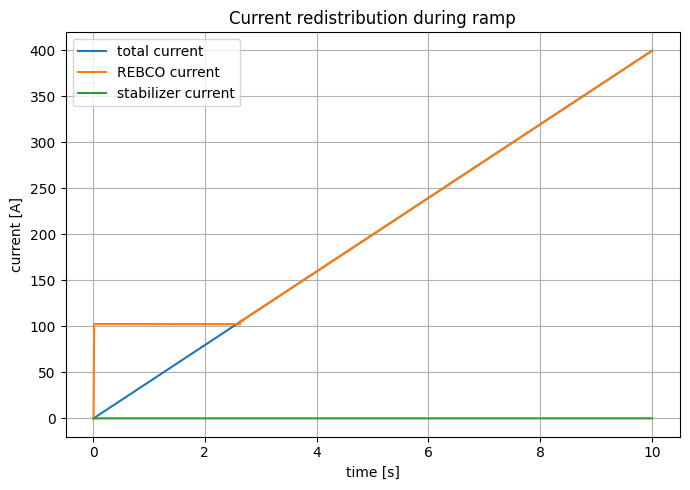

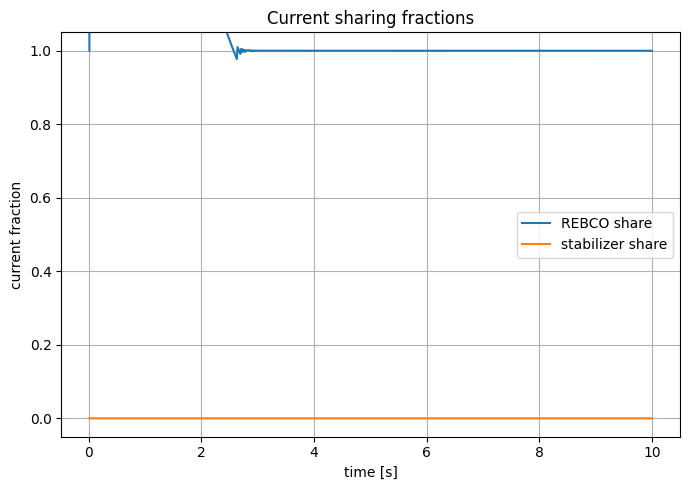

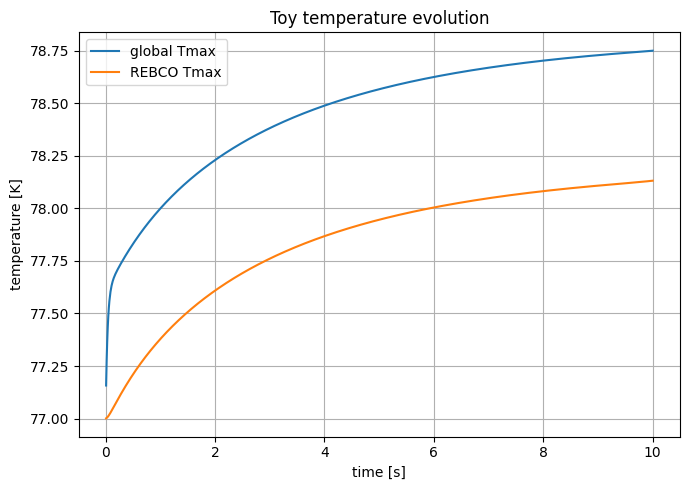

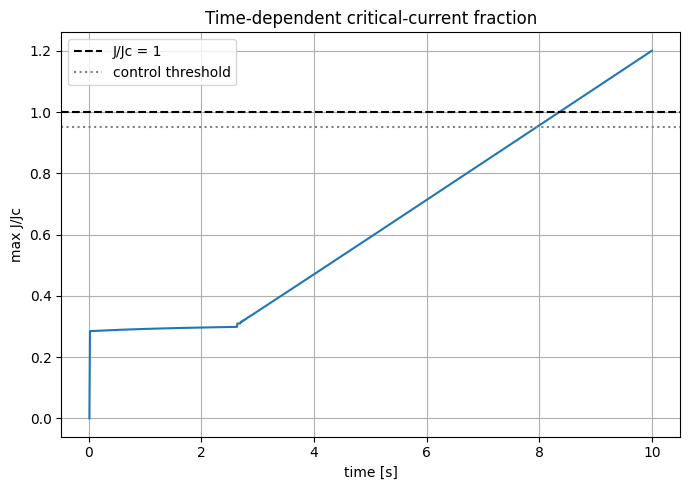

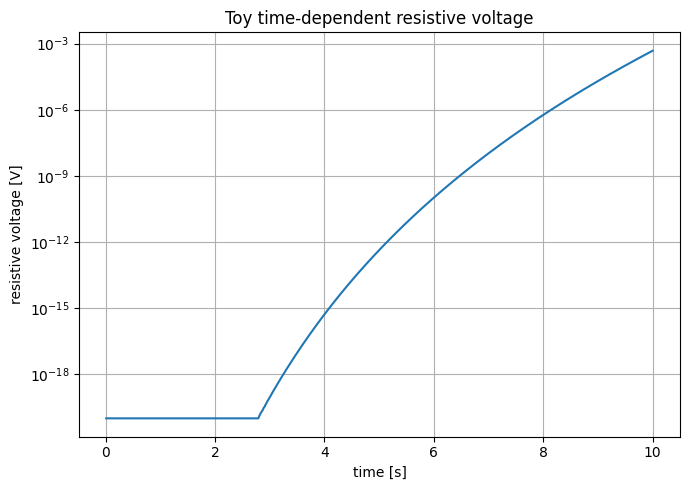

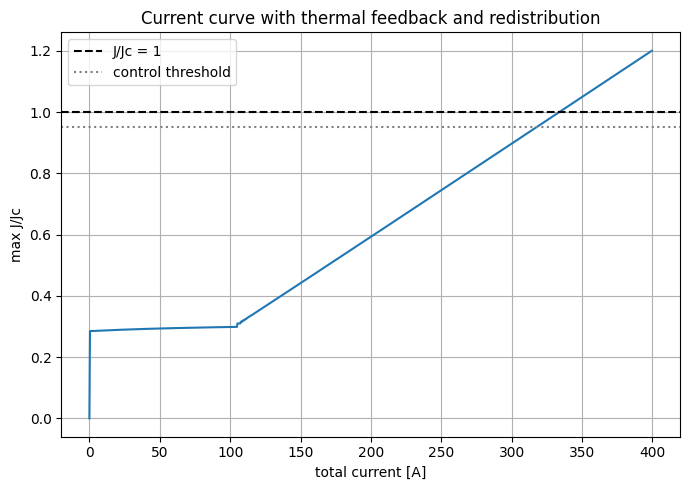

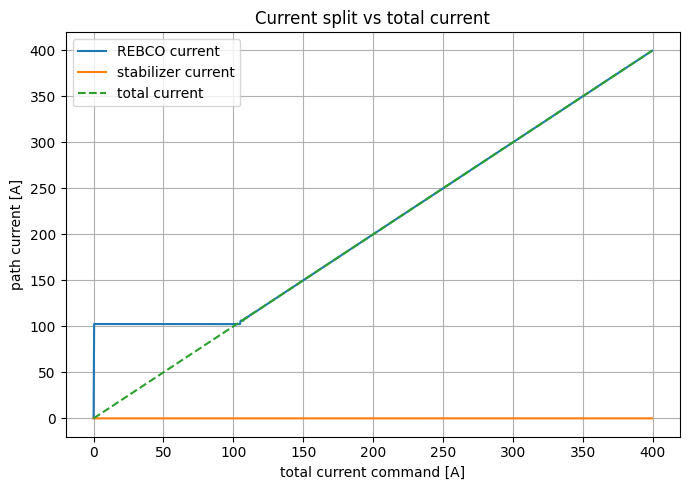

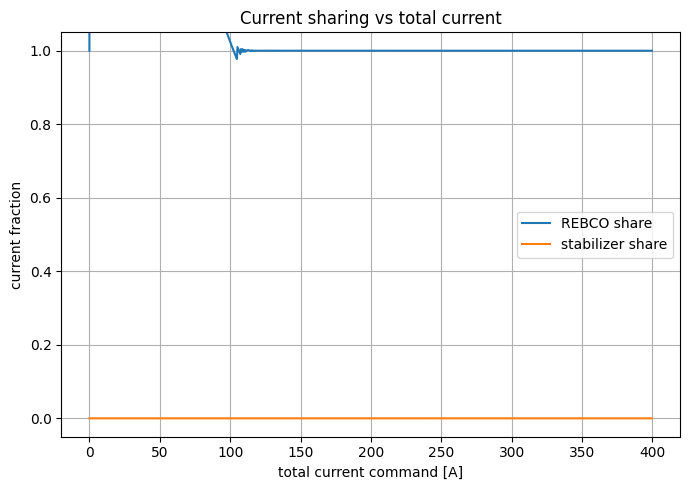

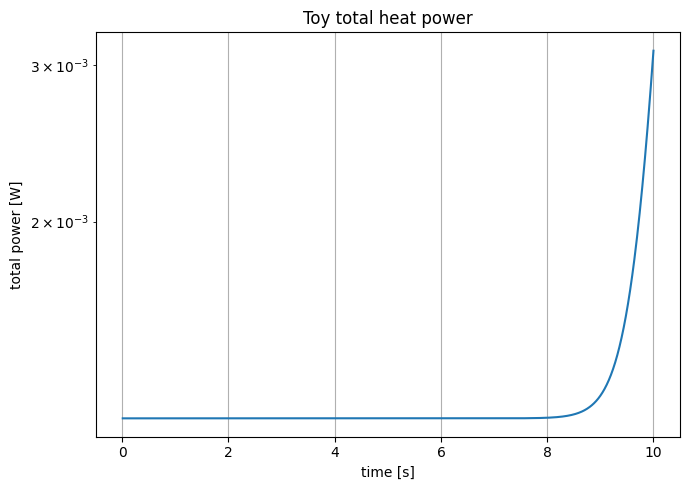

Final diagnostics
-----------------
I_total final = 399.6 A
I_REBCO final = 399.5815923906649 A
I_stabilizer final = 0.018407609335063736 A
REBCO current share final = 0.9999539349115738
Stabilizer current share final = 4.6065088426085424e-05
Tmax final = 78.7504492727531 K
Tmax_REBCO final = 78.1318639213724 K
max J/Jc final = 1.2005386247929957
V_tape final = 0.0004791579086895628 V
P_total final = 0.003115672839543264 W


In [34]:
run_current_ramp_with_temperature()

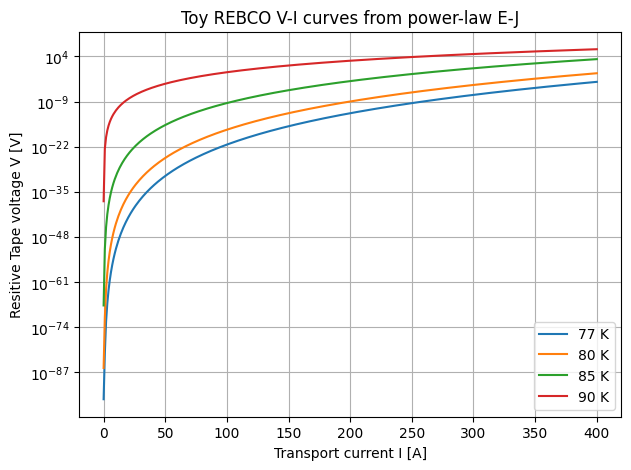

In [16]:
rebco = REBCOModel()

I_vals = np.linspace(0, 400, 401)
T_vals = [77, 80, 85, 90]

rebco_row = mesh.rows("rebco")[0]
A_rebco = mesh.width_m * mesh.dy[rebco_row]

plt.figure(figsize=(7, 5))

for T0 in T_vals:
    J_vals = I_vals / A_rebco
    E_vals = rebco.E(J_vals, T0)
    V_vals = E_vals * mesh.length_m

    plt.semilogy(I_vals, V_vals, label=str(T0) + " K")

plt.xlabel("Transport current I [A]")
plt.ylabel("Resitive Tape voltage V [V]")
plt.title("Toy REBCO V-I curves from power-law E-J")
plt.legend()
plt.grid(True)
plt.show()

77 K Ic = 360.0 A
80 K Ic = 288.0 A
85 K Ic = 168.0 A
90 K Ic = 42.0 A


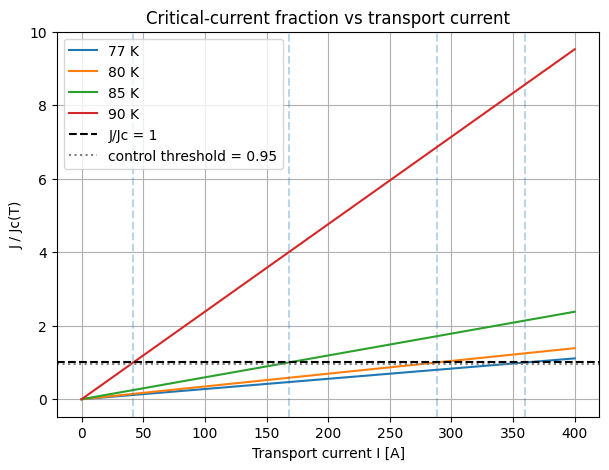

In [17]:
plt.figure(figsize=(7, 5))

for T0 in T_vals:
    Ic = rebco.Jc(T0) * A_rebco
    print(str(T0) + " K Ic =", round(Ic, 1), "A")
    plt.axvline(Ic, linestyle='--', alpha=0.3)
    J_vals = I_vals / A_rebco
    ratio = rebco.J_over_Jc(J_vals, T0)

    plt.plot(I_vals, ratio, label=str(T0) + " K")

plt.axhline(1.0, color="black", linestyle="--", label="J/Jc = 1")
plt.axhline(0.95, color="gray", linestyle=":", label="control threshold = 0.95")

plt.xlabel("Transport current I [A]")
plt.ylabel("J / Jc(T)")
plt.title("Critical-current fraction vs transport current")
plt.legend()
plt.grid(True)
plt.show()